HOUSE PRICE PREDICTION PROJECT

Dataset Loaded Successfully!
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  HousePrice  
0    -122.23       4.526  
1    -122.22       3.585  
2    -122.24       3.521  
3    -122.25       3.413  
4    -122.25       3.422  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non

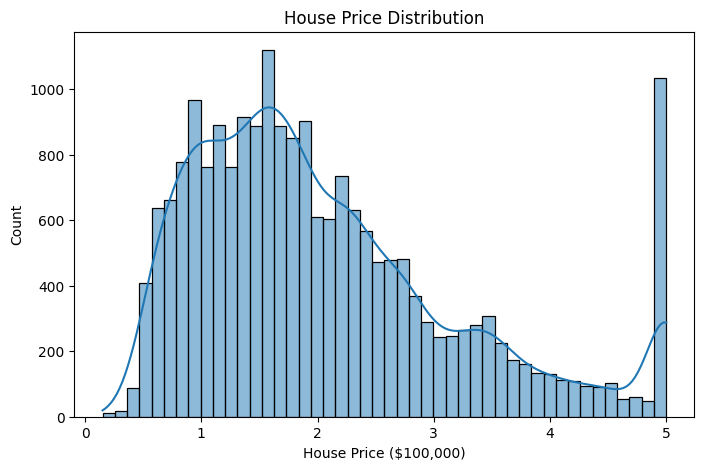

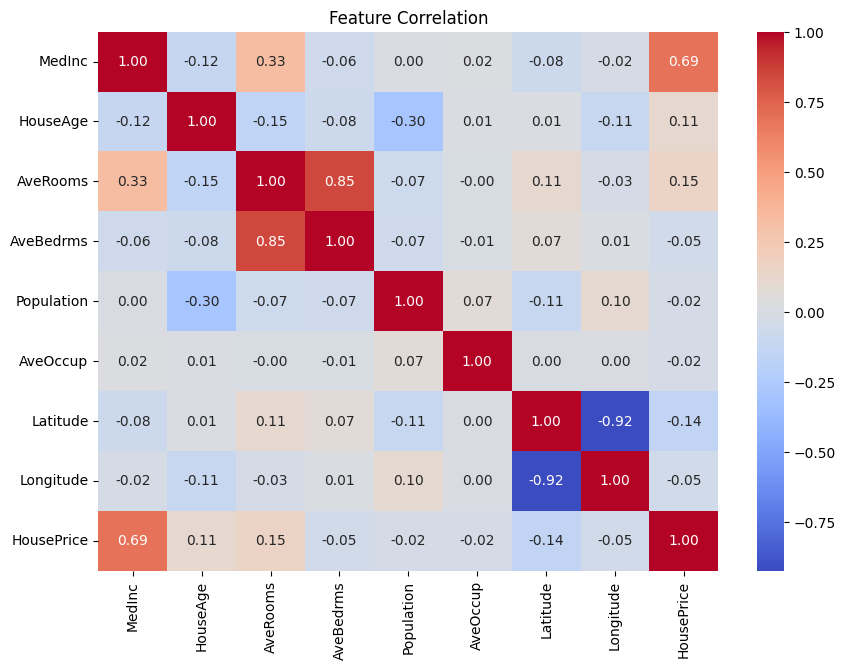


Training Data: (16512, 8)
Testing Data: (4128, 8)

Model Trained Successfully!

Prediction Results:
   Actual Price  Predicted Price
0       0.47700         0.719123
1       0.45800         1.764017
2       5.00001         2.709659
3       2.18600         2.838926
4       2.78000         2.604657
5       1.58700         2.011754
6       1.98200         2.645500
7       1.57500         2.168755
8       3.40000         2.740746
9       4.46600         3.915615

MODEL PERFORMANCE
MAE: 0.5332
MSE: 0.5559
RMSE: 0.7456
R2 Score: 0.5758
R2 Percentage: 57.58 %


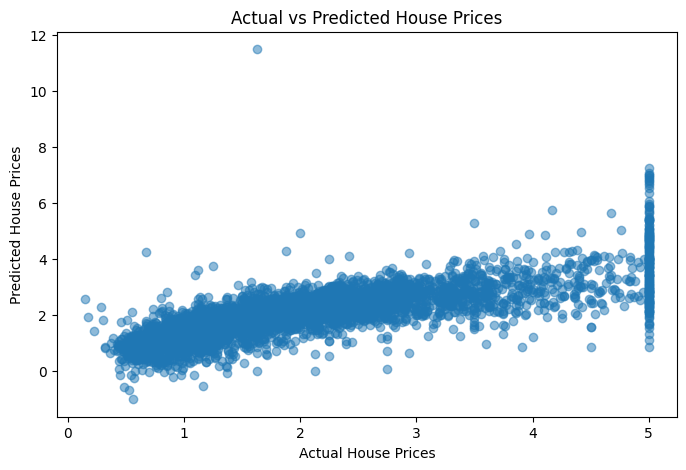


Model Saved Successfully!


       HOUSE PRICE PREDICTION FORM



PROJECT COMPLETED SUCCESSFULLY!


In [2]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

import ipywidgets as widgets
from IPython.display import display, clear_output

print("HOUSE PRICE PREDICTION PROJECT")
print("=" * 45)



housing = fetch_california_housing()

df = pd.DataFrame(
    housing.data,
    columns=housing.feature_names
)

df["HousePrice"] = housing.target

print("\nDataset Loaded Successfully!")
print(df.head())

# 3. DATA ANALYSIS

print("\nDataset Information:")
print(df.info())

print("\nDataset Shape:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
print(df.describe())

# 4. DATA VISUALIZATION

plt.figure(figsize=(8, 5))
sns.histplot(df["HousePrice"], kde=True)
plt.title("House Price Distribution")
plt.xlabel("House Price ($100,000)")
plt.show()



plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation")
plt.show()



X = df.drop("HousePrice", axis=1)
y = df["HousePrice"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)



model = LinearRegression()
model.fit(X_train, y_train)

print("\nModel Trained Successfully!")



y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

print("\nPrediction Results:")
print(results.head(10))



mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nMODEL PERFORMANCE")
print("=" * 35)
print("MAE:", round(mae, 4))
print("MSE:", round(mse, 4))
print("RMSE:", round(rmse, 4))
print("R2 Score:", round(r2, 4))
print("R2 Percentage:", round(r2 * 100, 2), "%")



plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")
plt.show()



joblib.dump(model, "house_price_model.pkl")
print("\nModel Saved Successfully!")



print("\n")
print("=" * 45)
print("       HOUSE PRICE PREDICTION FORM")
print("=" * 45)

income = widgets.FloatText(
    value=5.0, description="Income:"
)

age = widgets.FloatText(
    value=20, description="House Age:"
)

rooms = widgets.FloatText(
    value=6, description="Rooms:"
)

bedrooms = widgets.FloatText(
    value=1.2, description="Bedrooms:"
)

population = widgets.FloatText(
    value=1000, description="Population:"
)

occupancy = widgets.FloatText(
    value=3, description="Occupancy:"
)

latitude = widgets.FloatText(
    value=34.05, description="Latitude:"
)

longitude = widgets.FloatText(
    value=-118.25, description="Longitude:"
)

predict_button = widgets.Button(
    description="PREDICT HOUSE PRICE",
    button_style="success",
    icon="check"
)

output = widgets.Output()

def predict_house_price(b):

    with output:
        clear_output()

        new_house = pd.DataFrame([{
            "MedInc": income.value,
            "HouseAge": age.value,
            "AveRooms": rooms.value,
            "AveBedrms": bedrooms.value,
            "Population": population.value,
            "AveOccup": occupancy.value,
            "Latitude": latitude.value,
            "Longitude": longitude.value
        }])

        if not np.isfinite(new_house.to_numpy()).all():
            print("Please enter valid numbers.")
            return

        if (new_house["MedInc"] <= 0).any() or \
           (new_house["HouseAge"] <= 0).any() or \
           (new_house["AveRooms"] <= 0).any() or \
           (new_house["AveBedrms"] <= 0).any() or \
           (new_house["Population"] <= 0).any() or \
           (new_house["AveOccup"] <= 0).any() or \
           not (-90 <= latitude.value <= 90) or \
           not (-180 <= longitude.value <= 180):
            print("Please enter valid positive values and geographic coordinates.")
            return

        prediction = model.predict(new_house)[0]


        price = prediction * 100000

        print("=" * 40)
        print("       HOUSE PRICE PREDICTION")
        print("=" * 40)
        print("Estimated House Price: $", round(price, 2))
        print("=" * 40)

        if prediction >= 0:
            print("Prediction Completed Successfully!")
        else:
            print("Warning: Model returned a negative estimate.")

predict_button.on_click(predict_house_price)

display(
    widgets.VBox([
        income,
        age,
        rooms,
        bedrooms,
        population,
        occupancy,
        latitude,
        longitude,
        predict_button,
        output
    ])
)

print("\nPROJECT COMPLETED SUCCESSFULLY!")
